In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
df=pd.read_csv("/content/drive/MyDrive/gen ai/airline.passenger")
df

,Month,Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121
...,...,...
139,1960-08,606
140,1960-09,508
141,1960-10,461
142,1960-11,390


In [8]:
data=df.iloc[:,1:].values
data

array([[112],
       [118],
       [132],
       [129],
       [121],
       [135],
       [148],
       [148],
       [136],
       [119],
       [104],
       [118],
       [115],
       [126],
       [141],
       [135],
       [125],
       [149],
       [170],
       [170],
       [158],
       [133],
       [114],
       [140],
       [145],
       [150],
       [178],
       [163],
       [172],
       [178],
       [199],
       [199],
       [184],
       [162],
       [146],
       [166],
       [171],
       [180],
       [193],
       [181],
       [183],
       [218],
       [230],
       [242],
       [209],
       [191],
       [172],
       [194],
       [196],
       [196],
       [236],
       [235],
       [229],
       [243],
       [264],
       [272],
       [237],
       [211],
       [180],
       [201],
       [204],
       [188],
       [235],
       [227],
       [234],
       [264],
       [302],
       [293],
       [259],
       [229],
       [203],
      

In [11]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler(feature_range=(0,1))
data_scaled=scaler.fit_transform(data)
data_scaled

array([[0.01544402],
       [0.02702703],
       [0.05405405],
       [0.04826255],
       [0.03281853],
       [0.05984556],
       [0.08494208],
       [0.08494208],
       [0.06177606],
       [0.02895753],
       [0.        ],
       [0.02702703],
       [0.02123552],
       [0.04247104],
       [0.07142857],
       [0.05984556],
       [0.04054054],
       [0.08687259],
       [0.12741313],
       [0.12741313],
       [0.1042471 ],
       [0.05598456],
       [0.01930502],
       [0.06949807],
       [0.07915058],
       [0.08880309],
       [0.14285714],
       [0.11389961],
       [0.13127413],
       [0.14285714],
       [0.18339768],
       [0.18339768],
       [0.15444015],
       [0.11196911],
       [0.08108108],
       [0.11969112],
       [0.12934363],
       [0.14671815],
       [0.17181467],
       [0.14864865],
       [0.15250965],
       [0.22007722],
       [0.24324324],
       [0.26640927],
       [0.2027027 ],
       [0.16795367],
       [0.13127413],
       [0.173

In [12]:
x=[]
y=[]
time_step=12
for i in range(len(data_scaled)-time_step):
  x.append(data_scaled[i:(i+time_step),0])
  y.append(data_scaled[i+time_step,0])

In [15]:
import numpy as np
x=np.array(x)
y=np.array(y)
print(x.shape)
print(y.shape)

(132, 12)
(132,)


In [16]:
x=x.reshape(132,12,1)
x.shape

(132, 12, 1)

In [17]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [19]:
from keras.models import Sequential
from keras.layers import Dense,LSTM
model=Sequential()
model.add(LSTM(units=50,return_sequences=True,input_shape=(12,1)))
model.add(LSTM(units=50,return_sequences=True))
model.add(LSTM(units=50,return_sequences=True))
model.add(LSTM(units=50))
model.add(Dense(units=1))
model.compile(optimizer='adam',loss='mean_squared_error')
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 12, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 12, 50)         │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 12, 50)         │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,051 (277.54 KB)

 Trainable params: 71,051 (277.54 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.fit(x_train,y_train,validation_data=(x_test,y_test),epochs=100,batch_size=64)

Epoch 1/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 469ms/step - loss: 0.1857 - val_loss: 0.1114
Epoch 2/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.1440 - val_loss: 0.0757
Epoch 3/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.1004 - val_loss: 0.0375
Epoch 4/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.0532 - val_loss: 0.0136
Epoch 5/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - loss: 0.0190 - val_loss: 0.0438
Epoch 6/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 0.0443 - val_loss: 0.0450
Epoch 7/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - loss: 0.0367 - val_loss: 0.0196
Epoch 8/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 0.0194 - val_loss: 0.0122
Epoch 9/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.0212 - val_loss: 0.0148
Epoch 10/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 0.0264 - val_loss: 0.0160
Epoch 11/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 0.0269 - val_loss: 0.0137
Epoch 12/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.0221 - val_l

In [25]:
pred=model.predict(x_train)
pred=scaler.inverse_transform(pred)
print(pred)
actual=scaler.inverse_transform(y_train.reshape(-1,1))
print(actual)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
[[279.50482]
 [282.8534 ]
 [380.64178]
 [183.53902]
 [448.60092]
 [247.27187]
 [307.64108]
 [522.85394]
 [152.70796]
 [263.5373 ]
 [522.1288 ]
 [349.14465]
 [263.58725]
 [158.0694 ]
 [260.3092 ]
 [228.24866]
 [434.8935 ]
 [263.2409 ]
 [145.16438]
 [242.26704]
 [147.02454]
 [455.10617]
 [238.63431]
 [395.47702]
 [445.1302 ]
 [398.94028]
 [274.51373]
 [357.3788 ]
 [345.06445]
 [192.12971]
 [168.25798]
 [463.09558]
 [142.28925]
 [461.75165]
 [378.32086]
 [425.19656]
 [477.87845]
 [236.12724]
 [410.70386]
 [142.38123]
 [362.30988]
 [451.8548 ]
 [234.03098]
 [145.51929]
 [167.47801]
 [218.26265]
 [148.03299]
 [264.29834]
 [492.8756 ]
 [393.5952 ]
 [138.37437]
 [187.79834]
 [196.1837 ]
 [248.35779]
 [334.66824]
 [198.37971]
 [171.79909]
 [325.18726]
 [192.64671]
 [403.6749 ]
 [225.18137]
 [378.3563 ]
 [407.2632 ]
 [186.10518]
 [510.02005]
 [157.07272]
 [353.18616]
 [163.25204]
 [198.13997]
 [252.05348]
 [445.9766 ]
 [316.25763]
 [287.92532]
 [471.20044]


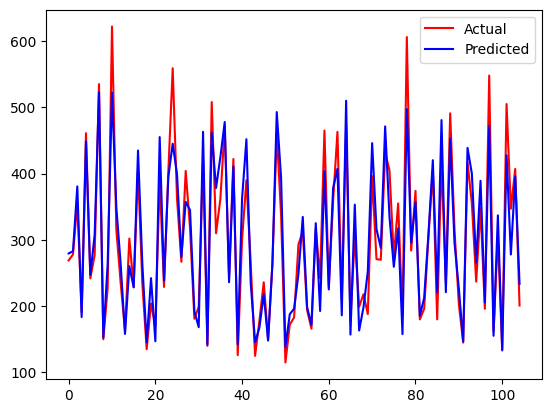

In [26]:
import matplotlib.pyplot as plt
plt.plot(actual,color='red',label='Actual')
plt.plot(pred,color='blue',label='Predicted')
plt.legend()
plt.show()